In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Question 1

In [71]:
GAMMA = 2 * np.pi * 5.234e6   # actual natural linewidth of Cesium F=0 to F'=1 in SI units
MU_B = 9.274009994e-24  # Bohr magneton in SI units
H_BAR = 1.054571817e-34  # Reduced Planck's constant in SI units
M_CS = 2.20694650e-25  # Mass of Cesium atom in kg
K_B = 1.380649e-23  # Boltzmann constant in SI units
C = 2.99792458e8  # Speed of light in SI units
A_0 = 5.29177210903e-11  # Bohr radius in meters
LAMBDA = 852.35e-9  # Wavelength of Cesium D2 line in meters
K = 2 * np.pi / LAMBDA  # Wave number in SI units
L = 1*10**-2 #extent of the MOT in meters


N_STEPS = 1000  # Number of steps for the simulation

def R_sc(s0, Delta):
    """
    Calculate the scattering rate R_sc based on the saturation parameter s0 and detuning Delta.

    Parameters:
    s0 (float): Saturation parameter.
    Delta (float): Detuning in units of the natural linewidth.

    Returns:
    float: Scattering rate R_sc.
    """
    return (s0 / (1 + s0 + (2 * Delta/GAMMA)**2)) * GAMMA/2 

def F_mot(z, v, s0=1, delta=-2*GAMMA, B=0.1):
    """
    Calculate the motional force F_mot based on position z and velocity v.

    Parameters:
    z (float): Position in meters.
    v (float): Velocity in meters per second.

    Returns:
    float: Motional force F_mot.
    """
    Delta_1 = delta + K*v + MU_B * B*z / H_BAR
    Delta_2 = delta - K*v - MU_B * B*z / H_BAR
    return (H_BAR * K) * ( R_sc(s0, Delta_1) - R_sc(s0, Delta_2) )

def captured_v(v_0, s0=1, delta=-2*GAMMA, B=0.1):
    """
    Calculate the captured velocity based on the initial velocity v_0.

    Parameters:
    v_0 (float): Initial velocity in meters per second.

    Returns:
    float: Captured velocity.
    """
    z, v = -L, v_0

    for i in range(N_STEPS):
        dt = 1e-6  # Time step in seconds
        v = v + F_mot(z, v, s0, delta, B) * dt / M_CS
        z = z + v * dt

        if abs(z) > L:
            return False  # Atom has escaped the MOT region
      
    return abs(z) <= L  # Atom is still within the MOT region after N_STEPS

def v_capture(s0, delta, Bgrad):
    for v0 in np.arange(1, 80, 1):          # m/s, 1 m/s resolution
        if not captured_v(v0, s0, delta, Bgrad):
            return v0 - 1
    return 80                             # never escaped in the scanned range


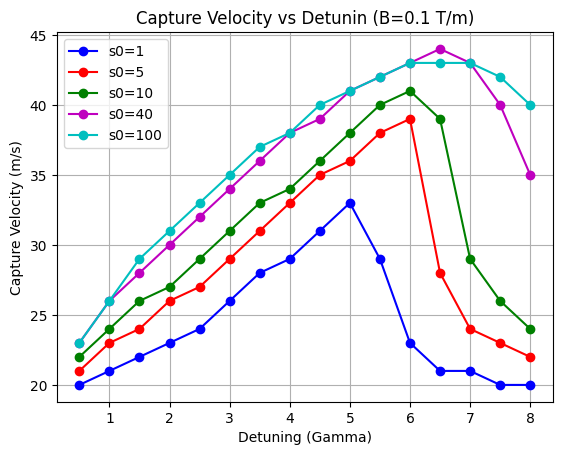

In [72]:
#detuning scan and plot results
detunings = np.arange(0.5*GAMMA, 8.5*GAMMA, GAMMA/2)
capture_velocities_1 = [v_capture(1, d, 0.1) for d in detunings]
capture_velocities_2 = [v_capture(5, d, 0.1) for d in detunings]
capture_velocities_3 = [v_capture(10, d, 0.1) for d in detunings]
capture_velocities_4 = [v_capture(40, d, 0.1) for d in detunings]
capture_velocities_5 = [v_capture(100, d, 0.1) for d in detunings]
plt.plot(detunings/GAMMA, capture_velocities_1, 'bo-', label='s0=1')
plt.plot(detunings/GAMMA, capture_velocities_2, 'ro-', label='s0=5')
plt.plot(detunings/GAMMA, capture_velocities_3, 'go-', label='s0=10')
plt.plot(detunings/GAMMA, capture_velocities_4, 'mo-', label='s0=40')
plt.plot(detunings/GAMMA, capture_velocities_5, 'co-', label='s0=100')
plt.xlabel('Detuning (Gamma)')
plt.ylabel('Capture Velocity (m/s)')
plt.title('Capture Velocity vs Detunin (B=0.1 T/m)')
plt.grid()
plt.legend()


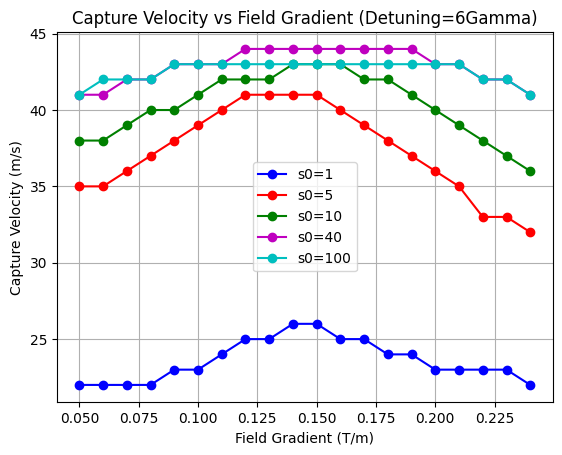

In [73]:
#field gradient scan and plot results
field_gradients = np.arange(0.05, 0.25, 0.01)
capture_velocities_1 = [v_capture(1, 6*GAMMA, B) for B in field_gradients]
capture_velocities_2 = [v_capture(5, 6*GAMMA, B) for B in field_gradients]
capture_velocities_3 = [v_capture(10, 6*GAMMA, B) for B in field_gradients]
capture_velocities_4 = [v_capture(40, 6*GAMMA, B) for B in field_gradients]
capture_velocities_5 = [v_capture(100, 6*GAMMA, B) for B in field_gradients]
plt.figure()
plt.plot(field_gradients, capture_velocities_1, 'bo-', label='s0=1')
plt.plot(field_gradients, capture_velocities_2, 'ro-', label='s0=5')
plt.plot(field_gradients, capture_velocities_3, 'go-', label='s0=10')
plt.plot(field_gradients, capture_velocities_4, 'mo-', label='s0=40')
plt.plot(field_gradients, capture_velocities_5, 'co-', label='s0=100')
plt.xlabel('Field Gradient (T/m)')
plt.ylabel('Capture Velocity (m/s)')
plt.title('Capture Velocity vs Field Gradient (Detuning=6Gamma)')
plt.grid()
plt.legend()    

In [74]:
# problem 1b acceleration
a = H_BAR * K / M_CS * GAMMA/2
print('acceleration:', a)
print('length of zeeman slower:', (200**2-30**2)/(2*a))

acceleration: 57920.17286977588
length of zeeman slower: 0.33753352297402506


In [75]:
# recoil velocity of cesium atom
v_recoil = H_BAR * K / M_CS
n_events = (200-30)/v_recoil
v_transverse = np.sqrt(2 * n_events / 3) *  v_recoil

print('recoil velocity:', v_recoil)
print('number of spontaneous emissions to slow down from 200 m/s to 30 m/s:', n_events)
print('transverse velocity spread due to spontaneous emission:', v_transverse)
print('transverse temperature gained:', M_CS * v_transverse**2 / K_B)

recoil velocity: 0.0035224615273068095
number of spontaneous emissions to slow down from 200 m/s to 30 m/s: 48261.70525416014
transverse velocity spread due to spontaneous emission: 0.6318324987115692
transverse temperature gained: 0.006381348209634991


## Question 2

In [77]:
# 2a

intensity = (100*10**-6 * K_B * 2*C) / (4*np.pi* A_0**3 * 1151)
print('intensity (W/cm^2):', intensity * 1e-4)  # Convert to W/cm^2
print('power (W):', intensity * np.pi * (50*10**-6)**2)  # Power in W

intensity (W/cm^2): 38622.945806807365
power (W): 3.0334390701665677


In [53]:
w = 50*10**-6
U_0 = 100*10**-6*K_B
z_R = np.pi * w**2 / (1064e-9) 
w_r = np.sqrt( 4*U_0 / (M_CS * w**2 ))
w_z = np.sqrt( 2*U_0 / (M_CS * z_R**2 ))

print('radial trap frequency (Hz):', w_r/(2*np.pi))
print('axial trap frequency (Hz):', w_z/(2*np.pi))

radial trap frequency (Hz): 503.5305924844568
axial trap frequency (Hz): 2.41175181908142


In [60]:
print('gravitational force (N):', M_CS * 9.81)
print('max restoring force when beam is vertical (N):', (3*np.sqrt(3)/8) * U_0 / z_R)
print('max restoring force when beam is horizontal (N):', 2 * U_0 * np.exp(-1/2) / w)

gravitational force (N): 2.1650145165000002e-24
max restoring force when beam is vertical (N): 1.2148619342637822e-25
max restoring force when beam is horizontal (N): 3.3496237952063505e-23


## Question 3

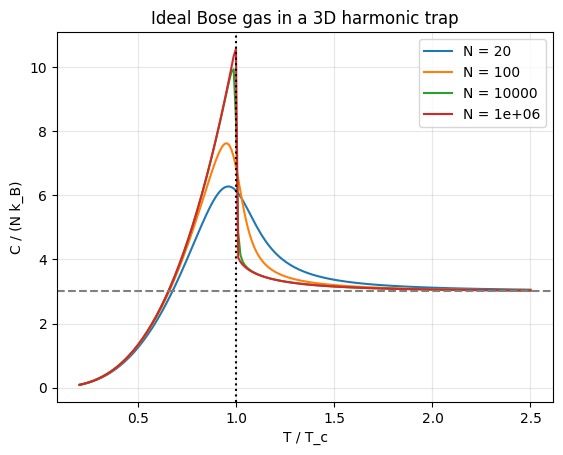

In [70]:

from scipy.optimize import brentq

k = np.arange(1, 20001)

def Li(n, z):
    return np.sum(z**k / k**n)

zeta3, zeta4 = Li(3, 1.0), Li(4, 1.0)

def C_over_NkB(t, N):   # t = T / Tc

    A = N * t**3 / zeta3
    z = brentq(lambda z: z/(1-z) + A*Li(3, z) - N, 1e-12, 1 - 1e-12)

    N0 = z/(1-z)
    Nth = A * Li(3, z)

    C = 12 * Nth * Li(4, z) / Li(3, z) - 9 * Nth**2 / (N0*(N0+1) + Nth * Li (2, z) / Li(3, z))
    return C / N

ts = np.linspace(0.2, 2.5, 200)
for N in [20, 100, 1e4, 1e6]:
    plt.plot(ts, [C_over_NkB(t, N) for t in ts], label=f'N = {N:g}')

plt.axhline(3, ls='--', c='gray')
plt.axvline(1, ls=':', c='k')
plt.xlabel('T / T_c'); plt.ylabel('C / (N k_B)')
plt.title('Ideal Bose gas in a 3D harmonic trap')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Question 4

In [ ]:
#AI used
from scipy.special import jv

def bessel_zeros(nu, n_zeros):
    """First n_zeros positive zeros of J_nu(x), any real order nu."""
    zeros = []
    # scan a fine grid, look for sign changes, then refine with brentq
    x = np.linspace(0.1, (n_zeros + nu/2 + 1) * np.pi, 20000)
    f = jv(nu, x)
    for i in np.where(np.sign(f[:-1]) != np.sign(f[1:]))[0]:
        zeros.append(brentq(lambda t: jv(nu, t), x[i], x[i+1]))
        if len(zeros) == n_zeros:
            break
    return np.array(zeros)

nu = 0.25
z = bessel_zeros(nu, 5)
print("zeros of J_1/4:", z)


zeros of J_1/4: [ 2.78088772  5.9061427   9.04238366 12.18134153 15.32136983]
asymptotic:     [ 2.74889357  5.89048623  9.03207888 12.17367153 15.31526419]


In [81]:
print("r_c/r_0:       ", 1/np.sqrt(2*z))

r_c/r_0:        [0.42402677 0.29095983 0.23514922 0.20259907 0.18064927]


In [83]:
1/np.sqrt(2*7*np.pi/8)

np.float64(0.42648723724584614)

In [ ]:

s = np.arange(1, 6)
print("asymptotic:    ", (s + nu/2 - 0.25) * np.pi)

In [87]:
M_H = 1.6735575e-27  # Mass of Hydrogen atom in kg
M_E = 9.1093837015e-31  # Mass of electron in kg
C6 = 6.5 #in a.u.
r_0 = (C6 * M_H/M_E)**(1/4)

print('length scale r_0 in Bohr radius:', r_0)
print('threshold core radius r_c in Bohr radius:', 1/np.sqrt(2*z[0]) * r_0)

length scale r_0 in Bohr radius: 10.453608948541733
threshold core radius r_c in Bohr radius: 4.432610027174557
